In [4]:
#Creo las carpetas del proyecto
import os

os.makedirs("data", exist_ok=True)
os.makedirs("extract", exist_ok=True)
os.makedirs("transform", exist_ok=True)
os.makedirs("load", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

In [5]:
%%writefile extract/extract.py

import pandas as pd

def extract_data(path):
    df = pd.read_csv(path)
    return df

Overwriting extract/extract.py


In [6]:
#Importa la función del módulo de extracción
from extract.extract import extract_data

#Extrae los datos
df_raw = extract_data("data/1970-2021_DISASTERS.xlsx - emdat data.csv")

#Valida la carga
print("Datos crudos:", df_raw.shape)

Datos crudos: (14644, 47)


In [7]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14644 entries, 0 to 14643
Data columns (total 47 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Dis No                           14644 non-null  object 
 1   Year                             14644 non-null  int64  
 2   Seq                              14644 non-null  int64  
 3   Glide                            1581 non-null   object 
 4   Disaster Group                   14644 non-null  object 
 5   Disaster Subgroup                14644 non-null  object 
 6   Disaster Type                    14644 non-null  object 
 7   Disaster Subtype                 11897 non-null  object 
 8   Disaster Subsubtype              1044 non-null   object 
 9   Event Name                       3645 non-null   object 
 10  Country                          14644 non-null  object 
 11  ISO                              14644 non-null  object 
 12  Region            

In [8]:
#Reviso los primeros registros de las columnas temporales
df_raw[['Start Year', 'Start Month', 'Start Day']].head(10)

,Start Year,Start Month,Start Day
0,1970,1.0,4.0
1,1970,1.0,NaN
2,1970,9.0,NaN
3,1970,11.0,12.0
4,1970,4.0,13.0
5,1970,7.0,NaN
6,1970,10.0,23.0
7,1970,8.0,NaN
8,1970,7.0,21.0
9,1970,10.0,2.0


In [9]:
#Cuenta los valores faltantes en cada columna
df_raw[['Start Year', 'Start Month', 'Start Day']].isnull().sum()

,0
Start Year,0
Start Month,268
Start Day,3067


In [10]:
%%writefile transform/transform.py

import pandas as pd

def transform_date(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    df["fecha"] = pd.to_datetime(
        dict(
            year=df["Start Year"],
            month=df["Start Month"],
            day=1
        ),
        errors="coerce"
    )

    return df


def clean_categories(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    columnas = ["Disaster Type", "Country", "Continent", "Region"]

    for columna in columnas:
        df[columna] = df[columna].str.strip()

    return df


def disasters_by_year(df: pd.DataFrame) -> pd.Series:
    counts = df["Start Year"].value_counts().sort_index()
    return counts


def disasters_by_type_continent(df: pd.DataFrame) -> pd.DataFrame:
    tabla = pd.crosstab(
        df["Disaster Type"],
        df["Continent"]
    )
    return tabla


def disasters_by_month(df: pd.DataFrame) -> pd.Series:
    counts = df["fecha"].dt.month.value_counts().sort_index()
    return counts


def disasters_by_type_year(df: pd.DataFrame) -> pd.DataFrame:
    df_reciente = df[df["Start Year"].between(2002, 2021)]

    tabla = pd.crosstab(
        df_reciente["Start Year"],
        df_reciente["Disaster Type"]
    )

    principales = tabla.sum().nlargest(5).index

    return tabla[principales]


def affected_by_continent(df: pd.DataFrame) -> pd.DataFrame:
    df_validos = df.dropna(subset=["Total Affected"])

    tabla = df_validos.groupby("Continent")["Total Affected"].agg(
        ["sum", "count"]
    )

    return tabla.sort_values("sum", ascending=False)

Writing transform/transform.py


In [11]:
#Pruebo la transformación
from transform.transform import transform_date

df = transform_date(df_raw)

df[["Start Year", "Start Month", "Start Day", "fecha"]].head(10)

,Start Year,Start Month,Start Day,fecha
0,1970,1.0,4.0,1970-01-01
1,1970,1.0,NaN,1970-01-01
2,1970,9.0,NaN,1970-09-01
3,1970,11.0,12.0,1970-11-01
4,1970,4.0,13.0,1970-04-01
5,1970,7.0,NaN,1970-07-01
6,1970,10.0,23.0,1970-10-01
7,1970,8.0,NaN,1970-08-01
8,1970,7.0,21.0,1970-07-01
9,1970,10.0,2.0,1970-10-01


In [12]:
#Compruebo el tipo de dato de la nueva columna
df["fecha"].dtype

dtype('<M8[ns]')

In [13]:
#Cuenta las fechas que no pudieron construirse
df["fecha"].isnull().sum()

np.int64(268)

In [14]:
#Selecciono las columnas categóricas que vamos a analizar
columnas = ["Disaster Type", "Country", "Continent", "Region"]

#Cuenta los valores faltantes
df[columnas].isnull().sum()

,0
Disaster Type,0
Country,0
Continent,0
Region,0


In [15]:
#Vemos los distintos tipos de desastres y su frecuencia
df["Disaster Type"].value_counts()

,count
Disaster Type,
Flood,5272
Storm,4005
Epidemic,1436
Earthquake,1137
Landslide,713
Drought,685
Extreme temperature,584
Wildfire,452
Volcanic activity,222


In [16]:
#Pruebo la limpieza
from transform.transform import clean_categories

df = clean_categories(df)

df["Disaster Type"].value_counts()

,count
Disaster Type,
Flood,5272
Storm,4005
Epidemic,1436
Earthquake,1137
Landslide,713
Drought,685
Extreme temperature,584
Wildfire,452
Volcanic activity,222


In [17]:
# Selecciona las variables numéricas
columnas_numericas = [
    "Total Deaths",
    "Total Affected",
    "Total Damages ('000 US$)"
]

# Reviso cantidad de valores faltantes
df[columnas_numericas].isnull().sum()

,0
Total Deaths,4445
Total Affected,3603
Total Damages ('000 US$),9781


In [18]:
# Obtengo las estadísticas descriptivas
df[columnas_numericas].describe()

,Total Deaths,Total Affected,Total Damages ('000 US$)
count,10199.000000,1.104100e+04,4.863000e+03
mean,361.813119,7.277392e+05,7.746866e+05
std,6495.045853,7.851210e+06,4.901266e+06
min,1.000000,1.000000e+00,2.000000e+00
25%,5.000000,6.320000e+02,1.000000e+04
50%,16.000000,5.736000e+03,7.100000e+04
75%,50.000000,5.600000e+04,3.500000e+05
max,300000.000000,3.300000e+08,2.100000e+08


In [19]:
#Cuenta filas completamente duplicadas
df.duplicated().sum()

np.int64(0)

In [20]:
#Verifica si hay identificadores de desastres repetidos
df["Dis No"].duplicated().sum()

np.int64(0)

In [21]:
from transform.transform import disasters_by_year

desastres_por_anio = disasters_by_year(df)

desastres_por_anio.head(10)

,count
Start Year,
1970,82
1971,63
1972,63
1973,64
1974,73
1975,67
1976,95
1977,144
1978,138


In [22]:
%%writefile load/load.py

import os
import matplotlib.pyplot as plt

def plot_disasters_by_year(counts, output_path):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    fig, ax = plt.subplots(figsize=(12, 5))

    counts.plot(kind="line", ax=ax, marker="o")

    ax.set_title("Evolución de los desastres naturales (1970-2021)")
    ax.set_xlabel("Año")
    ax.set_ylabel("Cantidad de desastres")
    ax.grid(True)

    fig.tight_layout()
    fig.savefig(output_path)
    plt.close(fig)


def plot_disasters_by_type_continent(tabla, output_path):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    principales = tabla.loc[
        tabla.sum(axis=1).nlargest(5).index
    ]

    ax = principales.plot(
        kind="bar",
        figsize=(12, 6)
    )

    ax.set_title("Principales tipos de desastres por continente")
    ax.set_xlabel("Tipo de desastre")
    ax.set_ylabel("Cantidad de desastres")
    ax.legend(title="Continente")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(output_path)
    plt.close()


def plot_disasters_by_month(counts, output_path):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    fig, ax = plt.subplots(figsize=(10, 5))

    counts.plot(kind="bar", ax=ax)

    ax.set_title("Distribución mensual de desastres naturales (1970-2021)")
    ax.set_xlabel("Mes")
    ax.set_ylabel("Cantidad de desastres")
    ax.set_xticklabels(
        ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"],
        rotation=0
    )

    fig.tight_layout()
    fig.savefig(output_path)
    plt.close(fig)


def plot_disasters_by_type_year(tabla, output_path):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    fig, ax = plt.subplots(figsize=(12, 6))

    tabla.plot(kind="line", ax=ax, marker="o")

    ax.set_title("Evolución de los principales desastres (2002-2021)")
    ax.set_xlabel("Año")
    ax.set_ylabel("Cantidad de desastres")
    ax.legend(title="Tipo de desastre")
    ax.grid(True)

    fig.tight_layout()
    fig.savefig(output_path)
    plt.close(fig)


def plot_affected_by_continent(tabla, output_path):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    fig, ax = plt.subplots(figsize=(10, 5))

    tabla["sum"].plot(kind="bar", ax=ax)

    ax.set_title("Personas afectadas por continente (1970-2021)")
    ax.set_xlabel("Continente")
    ax.set_ylabel("Total de personas afectadas registradas")

    plt.xticks(rotation=0)
    fig.tight_layout()
    fig.savefig(output_path)
    plt.close(fig)

Writing load/load.py


In [23]:
from load.load import plot_disasters_by_year

plot_disasters_by_year(
    desastres_por_anio,
    "outputs/desastres_por_anio.png"
)

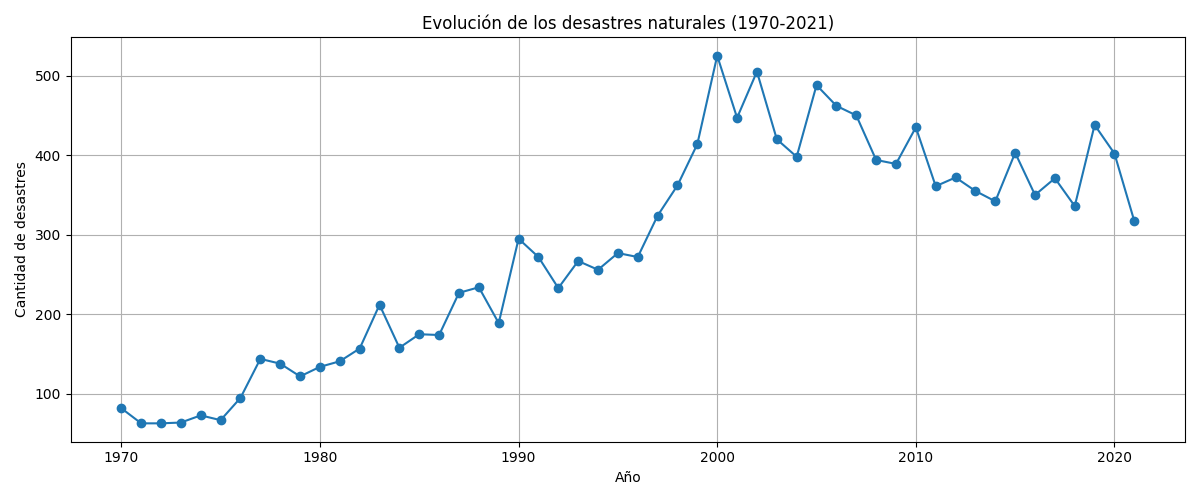

In [24]:
from IPython.display import Image, display

display(Image(filename="outputs/desastres_por_anio.png"))

Análisis del gráfico: Evolución de los desastres naturales.

Se observa una tendencia creciente en la cantidad de desastres naturales entre 1970 y 2021.

Durante los primeros años se ve un aumento progresivo, que a partir de 1990 se intensifica, alcanzando el máximo valor en el año 2000, con más de 500 eventos registrados.

Desde allí en adelante, la cantidad de desastres registrados por año presenta fluctuaciones y una disminución del máximo alcanzado, aunque se mantiene en mayor cantidad que de 1970 a 1990.

Podemos identificar el aumento o disminución en la cantidad de eventos registrados, pero lo que no podemos determinar son sus causas.

In [25]:
from transform.transform import disasters_by_type_continent

tabla_tipo_continente = disasters_by_type_continent(df)

tabla_tipo_continente

Continent,Africa,Americas,Asia,Europe,Oceania
Disaster Type,,,,,
Animal accident,1,0,0,0,0
Drought,291,153,166,44,31
Earthquake,53,226,671,137,50
Epidemic,861,162,340,46,27
Extreme temperature,20,104,180,272,8
Flood,1116,1204,2156,641,155
Glacial lake outburst,0,0,2,0,0
Impact,0,0,0,1,0
Insect infestation,74,3,13,1,2


In [26]:
from load.load import plot_disasters_by_type_continent

In [27]:
plot_disasters_by_type_continent(
    tabla_tipo_continente,
    "outputs/desastres_tipo_continente.png"
)

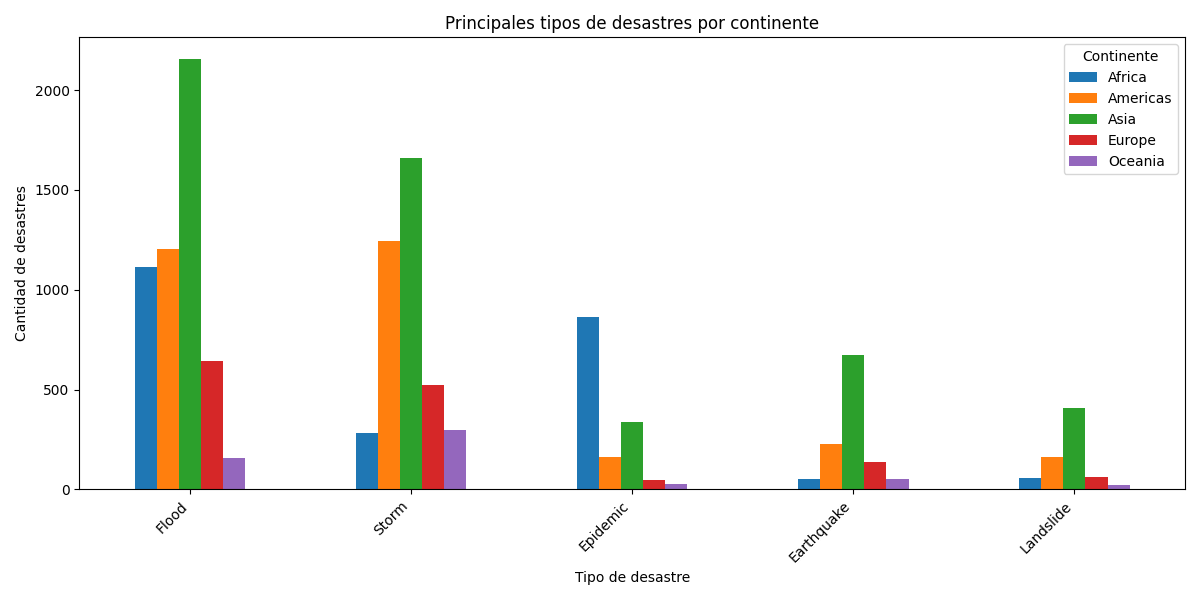

In [28]:
display(Image(filename="outputs/desastres_tipo_continente.png"))

Análisis del gráfico: Principales desastres por continente.

Acá cruzamos el tipo de desastre y el continente en el que sucedió.

Podemos observar que las inundaciones y las tormentas son los tipos de desastres más frecuentes, y que hay una marcada concentración en Asia. Quién también presenta la mayor cantidad de terremotos y deslizamientos de tierra, concentrando la mayor cantidad de registros en cuatro de las cinco categorías analizadas.

Por otro lado, observamos que África registra la mayor cantidad de epidemias.

Estos resultados muestran la cantidad de desastres registrados en cada continente, pero sin considerar su tamaño, la cantidad de habitantes ni las diferencias en la forma de registrar los eventos.

Es por eso que no podemos afirmar que un continente sea más peligroso que otro solamente porque tenga más desastres registrados.

In [29]:
from transform.transform import disasters_by_month

desastres_por_mes = disasters_by_month(df)

desastres_por_mes

,count
fecha,
1.0,1633
2.0,952
3.0,943
4.0,1033
5.0,1134
6.0,1226
7.0,1531
8.0,1522
9.0,1269


In [30]:
from load.load import plot_disasters_by_month

plot_disasters_by_month(
    desastres_por_mes,
    "outputs/desastres_por_mes.png"
)

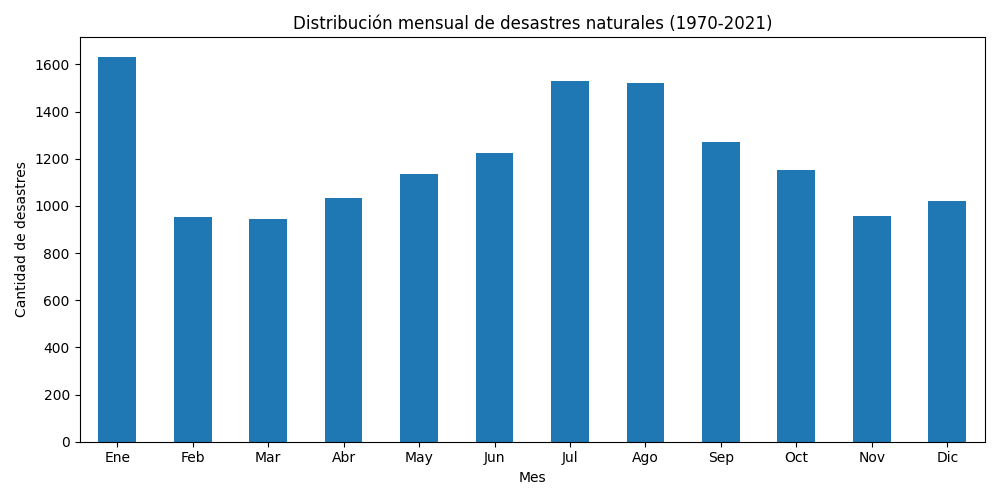

In [31]:
display(Image(filename="outputs/desastres_por_mes.png"))

Análisis del gráfico: Distribución mensual de los desastres.

Acá visualizamos la variación de la cantidad de desastres naturales registrados según el mes del año.

Podemos observar que enero presenta la mayor cantidad de registros, le siguen julio y agosto. Y por el contrario, marzo es el mes con menos eventos registrados.

Estas diferencias se podrían relacionar con fenómenos naturales que ocurren con mayor frecuencia en determinadas épocas del año, como tormentas, inundaciones o temperaturas extremas.

Sin embargo, como los datos corresponden a diferentes países y continentes, no podemos asegurar que exista una misma temporada de mayor riesgo en todo el mundo.

In [32]:
from transform.transform import disasters_by_type_year

tabla_tipo_anio = disasters_by_type_year(df)

tabla_tipo_anio

Disaster Type,Flood,Storm,Epidemic,Earthquake,Extreme temperature
Start Year,,,,,
2002,172,122,84,37,15
2003,158,86,60,40,25
2004,128,124,36,42,16
2005,193,130,56,25,30
2006,226,76,60,24,24
2007,218,105,36,21,25
2008,165,111,42,23,10
2009,151,87,44,22,25
2010,184,94,41,24,29


In [33]:
from load.load import plot_disasters_by_type_year

In [34]:
plot_disasters_by_type_year(
    tabla_tipo_anio,
    "outputs/desastres_tipo_anio.png"
)

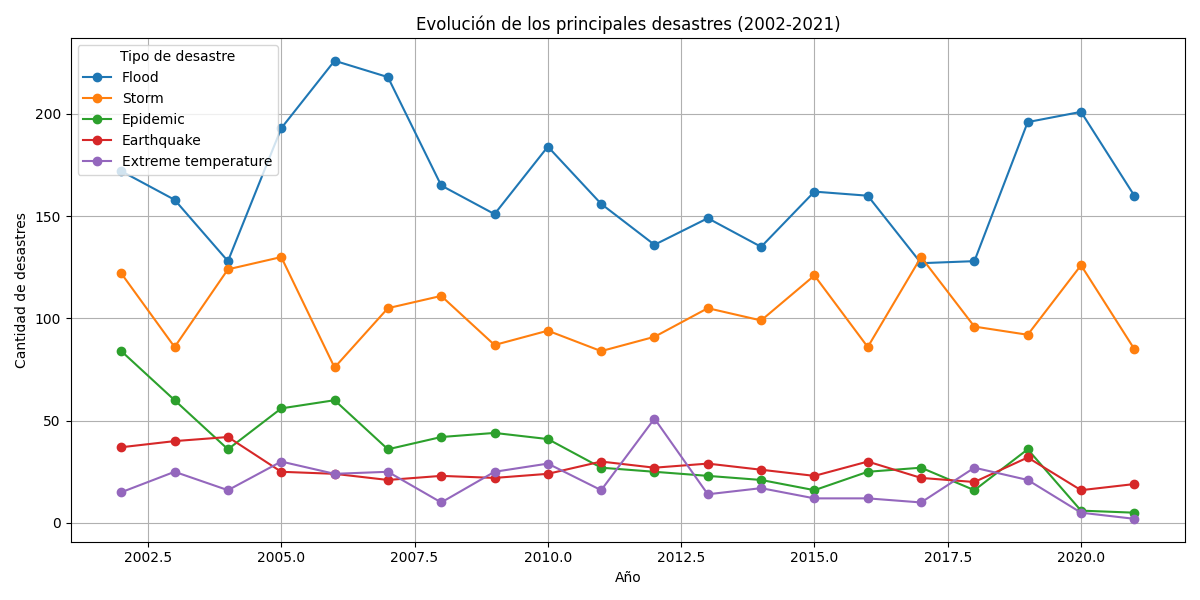

In [35]:
display(Image(filename="outputs/desastres_tipo_anio.png"))

Análisis del gráfico: Evolución de los 5 desastres más frecuentes.

Este gráfico muestra cómo evolucionaron los 5 tipos de desastres naturales más frecuentes durante los últimos 20 años del período estudiado.

Las inundaciones fueron los eventos más registrados, seguidas por las tormentas. Ambas presentan aumentos y disminuciones, sin mantener un crecimiento constante.

Las epidemias muestran una disminución en la cantidad de registros, mientras que los terremotos se mantienen más bien estables. Las temperaturas extremas presentan cantidades menores, aunque se ve un aumento importante en el año 2012.

No todos los desastres varían de la misma manera a través de los años, es por eso que lo ideal es analizar cada tipo por separado.

In [36]:
from transform.transform import affected_by_continent

tabla_afectados = affected_by_continent(df)

tabla_afectados

,sum,count
Continent,,
Asia,6.923120e+09,4645
Africa,6.054536e+08,2426
Americas,4.369688e+08,2522
Europe,4.311441e+07,985
Oceania,2.631214e+07,463


In [37]:
from load.load import plot_affected_by_continent

In [38]:
plot_affected_by_continent(
    tabla_afectados,
    "outputs/afectados_por_continente.png"
)

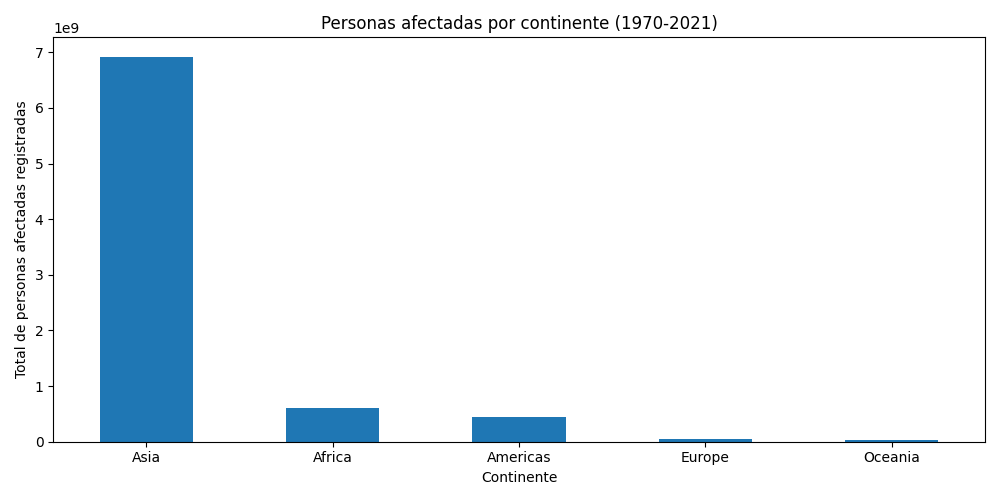

In [39]:
display(Image(filename="outputs/afectados_por_continente.png"))

Análisis del gráfico: Personas afectadas por continente

En este gráfico se puede observar la cantidad de personas afectadas por desastres naturales en cada continente entre 1970 y 2021.

Vemos que Asia presenta la mayor cantidad, con aproximadamente 6.923 millones de personas afectadas, superando ampliamente a los demás continentes. Le siguen África y América, y luego con valores mucho menores Europa y Oceanía.

Esta diferencia podría estar relacionada con la gran cantidad de habitantes que tienen algunos países asiáticos. Y además pueden haber personas que fueron afectadas por varios eventos y aparecen contabilizadas más de una vez.

Además, algunos desastres no tienen registrada la cantidad de personas afectadas, por lo que los resultados se basan únicamente en los eventos que cuentan con esa información.

In [40]:
tabla_tipo_continente.loc["Earthquake"]

,Earthquake
Continent,
Africa,53
Americas,226
Asia,671
Europe,137
Oceania,50


Análisis de la tabla: Terremotos por continente

Entre 1970 y 2021 se registraron 1137 terremotos.

Asia presenta la mayor cantidad con 671 registros, le sigue América con 226 y Europa con 137. África y Oceanía muestran cantidades más bajas.

Con esto podemos ver que los terremotos no se distribuyen de manera uniforme entre los continentes, sino que se concentran principalmente en Asia.

Sin embargo esto no nos permite determinar qué continente tiene mayor riesgo de sufrir un terremoto, sólo observar los que se han registrado a lo largo de los años.

In [41]:
tabla_tipo_continente.loc["Flood"]

,Flood
Continent,
Africa,1116
Americas,1204
Asia,2156
Europe,641
Oceania,155


Análisis de la tabla: Distribución de inundaciones por continente

Entre 1970 y 2021 se registraron en total 5.272 inundaciones.

Asia presenta la mayor cantidad con 2156 registros, seguida por América con 1204 y África con 1116. Europa y Oceanía muestran cantidades menores.

Estos resultados indican que las inundaciones se concentran principalmente en Asia, aunque también hay una presencia importante en América y África.

Esto no nos permite determinar qué continente tiene mayor riesgo de sufrir inundaciones, sólo observar las que se han registrado a lo largo de los años.

In [42]:
tabla_tipo_continente.loc["Storm"]

,Storm
Continent,
Africa,281
Americas,1244
Asia,1660
Europe,521
Oceania,299


Análisis de la tabla: Distribución de tormentas por continente.

Entre 1970 y 2021 se registraron 4005 tormentas.

Asia presenta la mayor cantidad con 1660 registros, seguida por América con 1244 y Europa con 521. Oceanía y África muestran cantidades menores.

Al igual que en los análisis anteriores, estamos comparando cantidades de eventos registrados, por lo que no podemos afirmar que un continente tenga mayor riesgo que otro solamente a partir de estos datos.